# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](https://www.researchgate.net/publication/236231158_Using_Data_Mining_for_Bank_Direct_Marketing_An_Application_of_the_CRISP-DM_Methodology) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

The study reports **17 marketing campaigns** conducted from May 2008 to November 2010, covering 79,354 contacts in its original collection. The [UCI Bank Marketing release](https://archive.ics.uci.edu/dataset/222/bank%2Bmarketing) specifies 41,188 records for the public `bank-additional-full.csv` variant used here.

Source for the campaign count: [Moro, Laureano, and Cortez (2011), *Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology*](https://www.researchgate.net/publication/236231158_Using_Data_Mining_for_Bank_Direct_Marketing_An_Application_of_the_CRISP-DM_Methodology), p. 2, Materials and Methods.

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('data/bank-additional-full.csv', sep=';')

In [ ]:
df.head()

### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



The public file contains **41,188 rows and 21 columns**. There are **no actual null/NA values**. The literal category `unknown` appears in `job` (330), `marital` (80), `education` (1,731), `default` (8,597), `housing` (990), and `loan` (990); decide how to handle these explicitly during modeling rather than treating them as pandas nulls. The existing numeric columns are already numeric and categorical columns are strings, so no raw-column dtype coercion is needed. `pdays = 999` is the documented sentinel for not previously contacted, not a missing value. For realistic pre-call prediction, exclude `duration`: it is only known after the call and leaks information about the outcome. Categorical encoding belongs to the feature-engineering step in Problem 5.

### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

In [ ]:
df.info()

**Business objective:** Prioritize outbound calls to customers most likely to subscribe to a term deposit, so the bank can achieve more subscriptions for a fixed call budget or make fewer calls for the same number of subscriptions. Predict `y` (`yes` or `no`) using only information available before the call. For the initial model, use the seven bank-client features specified in Problem 5; do not use call duration, which is known only after the call.

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

In [ ]:
# Use only the seven bank-client attributes; keep raw values for future pipelines.
bank_client_features = ["age", "job", "marital", "education", "default", "housing", "loan"]
X_raw = df[bank_client_features].copy()
y = df["y"].map({"no": 0, "yes": 1}).astype("int8")

# Keep literal "unknown" values as categories. Fit one-hot categories after splitting.
print(f"Features: {len(bank_client_features)}; rows: {len(X_raw):,}; target counts (0=no, 1=yes):")
y.value_counts().sort_index().rename(index={0: "no", 1: "yes"})


In [ ]:
# Inspect the seven raw predictors before encoding.
X_raw.head()


In [ ]:
# Age stays numeric; the six categorical fields will be one-hot encoded using training data only.
X_raw.dtypes


### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [ ]:
# Create a reproducible 80/20 split, sampling each target class separately.
from numpy.random import default_rng

test_size = 0.20
split_seed = 42
rng = default_rng(split_seed)
test_indices = []
for class_value in sorted(y.unique()):
    class_indices = y.index[y == class_value].to_numpy().copy()
    rng.shuffle(class_indices)
    n_test = int(round(len(class_indices) * test_size))
    test_indices.extend(class_indices[:n_test])

test_indices = pd.Index(test_indices)
train_indices = X_raw.index.difference(test_indices)
X_train_raw = X_raw.loc[train_indices].copy()
X_test_raw = X_raw.loc[test_indices].copy()
y_train = y.loc[train_indices].copy()
y_test = y.loc[test_indices].copy()


In [ ]:
# One-hot encode with the training categories, then align the holdout to that schema.
categorical_features = ["job", "marital", "education", "default", "housing", "loan"]
X_train = pd.get_dummies(X_train_raw, columns=categorical_features, dtype=int)
X_test = pd.get_dummies(X_test_raw, columns=categorical_features, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)


In [ ]:
# Verify split sizes, class balance, and matching encoded feature schemas.
split_summary = pd.DataFrame({
    "Rows": [len(X_train_raw), len(X_test_raw)],
    "No (0)": [int((y_train == 0).sum()), int((y_test == 0).sum())],
    "Yes (1)": [int((y_train == 1).sum()), int((y_test == 1).sum())],
}, index=["Train", "Test"])
assert set(X_train_raw.columns) == set(bank_client_features)
assert set(X_test_raw.columns) == set(bank_client_features)
assert train_indices.intersection(test_indices).empty
assert len(train_indices) + len(test_indices) == len(df)
assert X_train.columns.equals(X_test.columns)
split_summary


### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [ ]:
# A majority-class baseline learns its prediction from training labels only.
baseline_prediction = int(y_train.mode().iat[0])
baseline_train_predictions = pd.Series(baseline_prediction, index=y_train.index)
baseline_test_predictions = pd.Series(baseline_prediction, index=y_test.index)
baseline_train_accuracy = (baseline_train_predictions == y_train).mean()
baseline_test_accuracy = (baseline_test_predictions == y_test).mean()
baseline_positive_recall = ((baseline_test_predictions == 1) & (y_test == 1)).sum() / (y_test == 1).sum()


In [ ]:
baseline_metrics = pd.DataFrame({
    "Metric": ["Majority class predicted", "Train accuracy", "Test accuracy", "Test recall (yes)"] ,
    "Value": ["no" if baseline_prediction == 0 else "yes", baseline_train_accuracy, baseline_test_accuracy, baseline_positive_recall],
})
baseline_metrics


In [ ]:
print(
    f"The majority-class baseline predicts {'no' if baseline_prediction == 0 else 'yes'} for every customer. "
    f"Its held-out accuracy is {baseline_test_accuracy:.3%}, but its recall for subscriptions is "
    f"{baseline_positive_recall:.1%}; compare later models against both metrics."
)


### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [1]:
from time import perf_counter
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression()
fit_start = perf_counter()
logistic_model.fit(X_train, y_train)
logistic_train_time = perf_counter() - fit_start

### Problem 9: Score the Model

What is the accuracy of your model?

In [2]:
logistic_train_accuracy = logistic_model.score(X_train, y_train)
logistic_test_accuracy = logistic_model.score(X_test, y_test)
print(f"Train accuracy: {logistic_train_accuracy:.4%}")
print(f"Test accuracy: {logistic_test_accuracy:.4%}")

Train accuracy: 88.7344%
Test accuracy: 88.7351%


### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [3]:
from time import perf_counter
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

model_results = [{
    "Model": "Logistic Regression",
    "Train Time": logistic_train_time,
    "Train Accuracy": logistic_train_accuracy,
    "Test Accuracy": logistic_test_accuracy,
}]

for model_name, model in [
    ("KNN", KNeighborsClassifier()),
    ("Decision Tree", DecisionTreeClassifier()),
    ("SVM", SVC()),
]:
    fit_start = perf_counter()
    model.fit(X_train, y_train)
    fit_time = perf_counter() - fit_start
    model_results.append({
        "Model": model_name,
        "Train Time": fit_time,
        "Train Accuracy": model.score(X_train, y_train),
        "Test Accuracy": model.score(X_test, y_test),
    })

model_comparison = pd.DataFrame(
    model_results,
    columns=["Model", "Train Time", "Train Accuracy", "Test Accuracy"],
)

In [4]:
model_comparison.round(4)

Model,Train Time,Train Accuracy,Test Accuracy
Logistic Regression,1.7518,0.8873,0.8874
KNN,0.0246,0.8922,0.8782
Decision Tree,0.2826,0.9167,0.8662
SVM,20.4543,0.8873,0.8874


In [5]:
print("Train Time is measured in seconds around fit() only; timing is machine-specific.")
print("Decision Tree results may vary across runs or software versions.")
print("Logistic Regression emitted a ConvergenceWarning at its default 100-iteration limit; default settings were retained.")
print("Its test accuracy is essentially the same as the 88.735% majority-class baseline; accuracy alone does not show whether positive subscriptions were identified.")

Train Time is measured in seconds around fit() only; timing is machine-specific.
Decision Tree results may vary across runs or software versions.
Logistic Regression emitted a ConvergenceWarning at its default 100-iteration limit; default settings were retained.
Its test accuracy is essentially the same as the 88.735% majority-class baseline; accuracy alone does not show whether positive subscriptions were identified.


### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

In [6]:
import json
import warnings
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, average_precision_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# Verify this tuning stage uses the exact existing stratified split.
assert len(X_train_raw) == 32_950 and len(X_test_raw) == 8_238
assert X_train_raw.index.equals(X_train.index)
assert X_test_raw.index.equals(X_test.index)
assert y_train.index.equals(X_train_raw.index)
assert y_test.index.equals(X_test_raw.index)
assert X_train_raw.index.intersection(X_test_raw.index).empty
assert X_train.columns.equals(X_test.columns)
assert X_train_raw.columns.tolist() == ["age", "job", "marital", "education", "default", "housing", "loan"]

p11_categorical_features = [column for column in X_train_raw.columns if column != "age"]
p11_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), p11_categorical_features),
        ("numeric", StandardScaler(), ["age"]),
    ]
)
p11_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
for p11_fold_train, p11_fold_valid in p11_cv.split(X_train_raw, y_train):
    p11_fold_train_ids = X_train_raw.index[p11_fold_train]
    p11_fold_valid_ids = X_train_raw.index[p11_fold_valid]
    assert p11_fold_train_ids.intersection(p11_fold_valid_ids).empty
    assert p11_fold_valid_ids.intersection(X_test_raw.index).empty

p11_model_specs = [
    (
        "Logistic Regression",
        LogisticRegression(max_iter=1000),
        {
            "classifier__C": [0.1, 1.0],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
    (
        "KNN",
        KNeighborsClassifier(),
        {
            "classifier__n_neighbors": [5, 15],
            "classifier__weights": ["uniform", "distance"],
        },
    ),
    (
        "Decision Tree",
        DecisionTreeClassifier(random_state=42),
        {
            "classifier__max_depth": [None, 10, 20],
            "classifier__min_samples_leaf": [1, 5],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
    (
        "SVM",
        SVC(),
        [
            {"classifier__C": [0.1], "classifier__class_weight": [None]},
            {"classifier__C": [1.0], "classifier__class_weight": [None]},
            {"classifier__C": [1.0], "classifier__class_weight": ["balanced"]},
        ],
    ),
]

# Each pipeline learns category levels and age scaling inside each CV training fold.
p11_searches = {}
p11_warnings = []
with warnings.catch_warnings(record=True) as p11_caught_warnings:
    warnings.simplefilter("always")
    for p11_name, p11_classifier, p11_param_grid in p11_model_specs:
        p11_pipeline = Pipeline(
            [
                ("preprocess", p11_preprocessor),
                ("classifier", p11_classifier),
            ]
        )
        p11_search = GridSearchCV(
            estimator=p11_pipeline,
            param_grid=p11_param_grid,
            scoring="average_precision",
            cv=p11_cv,
            refit=True,
            n_jobs=1,
            return_train_score=False,
            error_score="raise",
        )
        p11_search.fit(X_train_raw, y_train)
        p11_searches[p11_name] = p11_search
    p11_warnings = [
        f"{type(warning.message).__name__}: {warning.message}"
        for warning in p11_caught_warnings
    ]

# All four configurations are chosen before the held-out split is evaluated.
p11_results = []
for p11_name, p11_search in p11_searches.items():
    p11_best = p11_search.best_estimator_
    if callable(getattr(p11_best, "decision_function", None)):
        p11_test_scores = p11_best.decision_function(X_test_raw)
    else:
        p11_test_scores = p11_best.predict_proba(X_test_raw)[:, 1]
    p11_test_ap = average_precision_score(y_test, p11_test_scores)
    p11_test_accuracy = accuracy_score(y_test, p11_best.predict(X_test_raw))
    p11_best_parameters = {
        key.removeprefix("classifier__"): value
        for key, value in p11_search.best_params_.items()
    }
    p11_metrics = [p11_search.best_score_, p11_test_ap, p11_test_accuracy]
    assert all(np.isfinite(metric) and 0.0 <= metric <= 1.0 for metric in p11_metrics)
    p11_results.append(
        {
            "Model": p11_name,
            "Best Parameters": json.dumps(p11_best_parameters, sort_keys=True),
            "Mean CV AP": float(p11_search.best_score_),
            "Test Average Precision": float(p11_test_ap),
            "Test Accuracy": float(p11_test_accuracy),
        }
    )

p11_results_table = pd.DataFrame(
    p11_results,
    columns=["Model", "Best Parameters", "Mean CV AP", "Test Average Precision", "Test Accuracy"],
)
p11_test_prevalence = float(y_test.mean())
p11_constant_score_ap = average_precision_score(
    y_test, np.full(len(y_test), p11_test_prevalence)
)
p11_majority_label = int(y_train.mode().iat[0])
p11_majority_accuracy = accuracy_score(
    y_test, np.full(len(y_test), p11_majority_label)
)
p11_cv_winner = p11_results_table.loc[p11_results_table["Mean CV AP"].idxmax(), "Model"]
assert len(p11_results_table) == 4
assert abs(p11_constant_score_ap - p11_test_prevalence) < 1e-12
p11_results_table.round(4)


Model,Best Parameters,Mean CV AP,Test Average Precision,Test Accuracy
Logistic Regression,"{""C"": 0.1, ""class_weight"": null}",0.2049,0.1888,0.8874
KNN,"{""n_neighbors"": 15, ""weights"": ""uniform""}",0.1856,0.1750,0.8860
Decision Tree,"{""class_weight"": ""balanced"", ""max_depth"": 10, ""min_samples_leaf"": 5}",0.2086,0.1958,0.6548
SVM,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.1972,0.1818,0.6272


In [7]:
print(f"Model selection used three-fold training-only average precision; highest mean CV AP: {p11_cv_winner} ({p11_results_table['Mean CV AP'].max():.4f}).")
print(f"Test constant-score average precision equals the positive prevalence: {p11_constant_score_ap:.4f}; test majority-class accuracy is {p11_majority_accuracy:.4f}.")
print("Preprocessing is fitted within each training fold; test data was evaluated only after all best configurations were selected.")
if p11_warnings:
    print("Warnings: " + " | ".join(p11_warnings))
else:
    print("Warnings: none.")


Model selection used three-fold training-only average precision; highest mean CV AP: Decision Tree (0.2086).
Test constant-score average precision equals the positive prevalence: 0.1126; test majority-class accuracy is 0.8874.
Preprocessing is fitted within each training fold; test data was evaluated only after all best configurations were selected.
Warnings: none.


## Rubric Support: Training-Only Analysis


In [8]:
# All summaries below use the existing training rows and seven pre-call predictors.
p11_training_eda = X_train_raw.copy()
p11_training_eda["subscribed"] = y_train.astype(int)
p11_training_eda["subscription"] = p11_training_eda["subscribed"].map({0: "no", 1: "yes"})
p11_training_eda["housing_loan_group"] = (
    "housing=" + p11_training_eda["housing"] + ", loan=" + p11_training_eda["loan"]
)
p11_relevant_nulls = int(p11_training_eda[["age", "job", "marital", "education", "default", "housing", "loan", "subscribed"]].isna().sum().sum())
assert p11_relevant_nulls == 0
p11_unknown_counts = {
    column: int((X_train_raw[column] == "unknown").sum())
    for column in ["job", "marital", "education", "default", "housing", "loan"]
}
p11_age_summary = (
    p11_training_eda.groupby("subscription", observed=True)["age"]
    .agg(n="size", mean_age="mean", median_age="median")
    .reindex(["no", "yes"])
)
p11_housing_loan_summary = (
    p11_training_eda.groupby(["housing", "loan"], observed=True)
    .agg(n=("subscribed", "size"), subscribers=("subscribed", "sum"), subscription_rate=("subscribed", "mean"))
    .reset_index()
)
p11_housing_loan_summary["subscription_rate_pct"] = 100 * p11_housing_loan_summary["subscription_rate"]
p11_housing_loan_summary["housing_loan_label"] = (
    "housing=" + p11_housing_loan_summary["housing"] + ", loan=" + p11_housing_loan_summary["loan"]
)
print(f"Training rows: {len(X_train_raw):,}; predictors: {X_train_raw.shape[1]}; target yes rate: {y_train.mean():.2%}.")
print(f"Null cells in selected predictors and target: {p11_relevant_nulls}. No imputation was needed. Literal 'unknown' counts by category: {p11_unknown_counts}.")
print("Age by subscription status (age in years):")
print(p11_age_summary.round(1).to_string())
print("\nSubscription rate by housing and loan group (n is the denominator):")
print(p11_housing_loan_summary[["housing", "loan", "n", "subscribers", "subscription_rate_pct"]].sort_values(["housing", "loan"]).round({"subscription_rate_pct": 2}).to_string(index=False))


Training rows: 32,950; predictors: 7; target yes rate: 11.27%.
Null cells in selected predictors and target: 0. No imputation was needed. Literal 'unknown' counts by category: {'job': 255, 'marital': 65, 'education': 1393, 'default': 6904, 'housing': 774, 'loan': 774}.
Age by subscription status (age in years):
                  n  mean_age  median_age
subscription                             
no            29238      39.9        38.0
yes            3712      40.9        37.0

Subscription rate by housing and loan group (n is the denominator):
housing    loan     n  subscribers  subscription_rate_pct
     no      no 12881         1397                  10.85
     no     yes  2043          217                  10.62
unknown unknown   774           86                  11.11
    yes      no 14323         1679                  11.72
    yes     yes  2929          333                  11.37


### Visual EDA


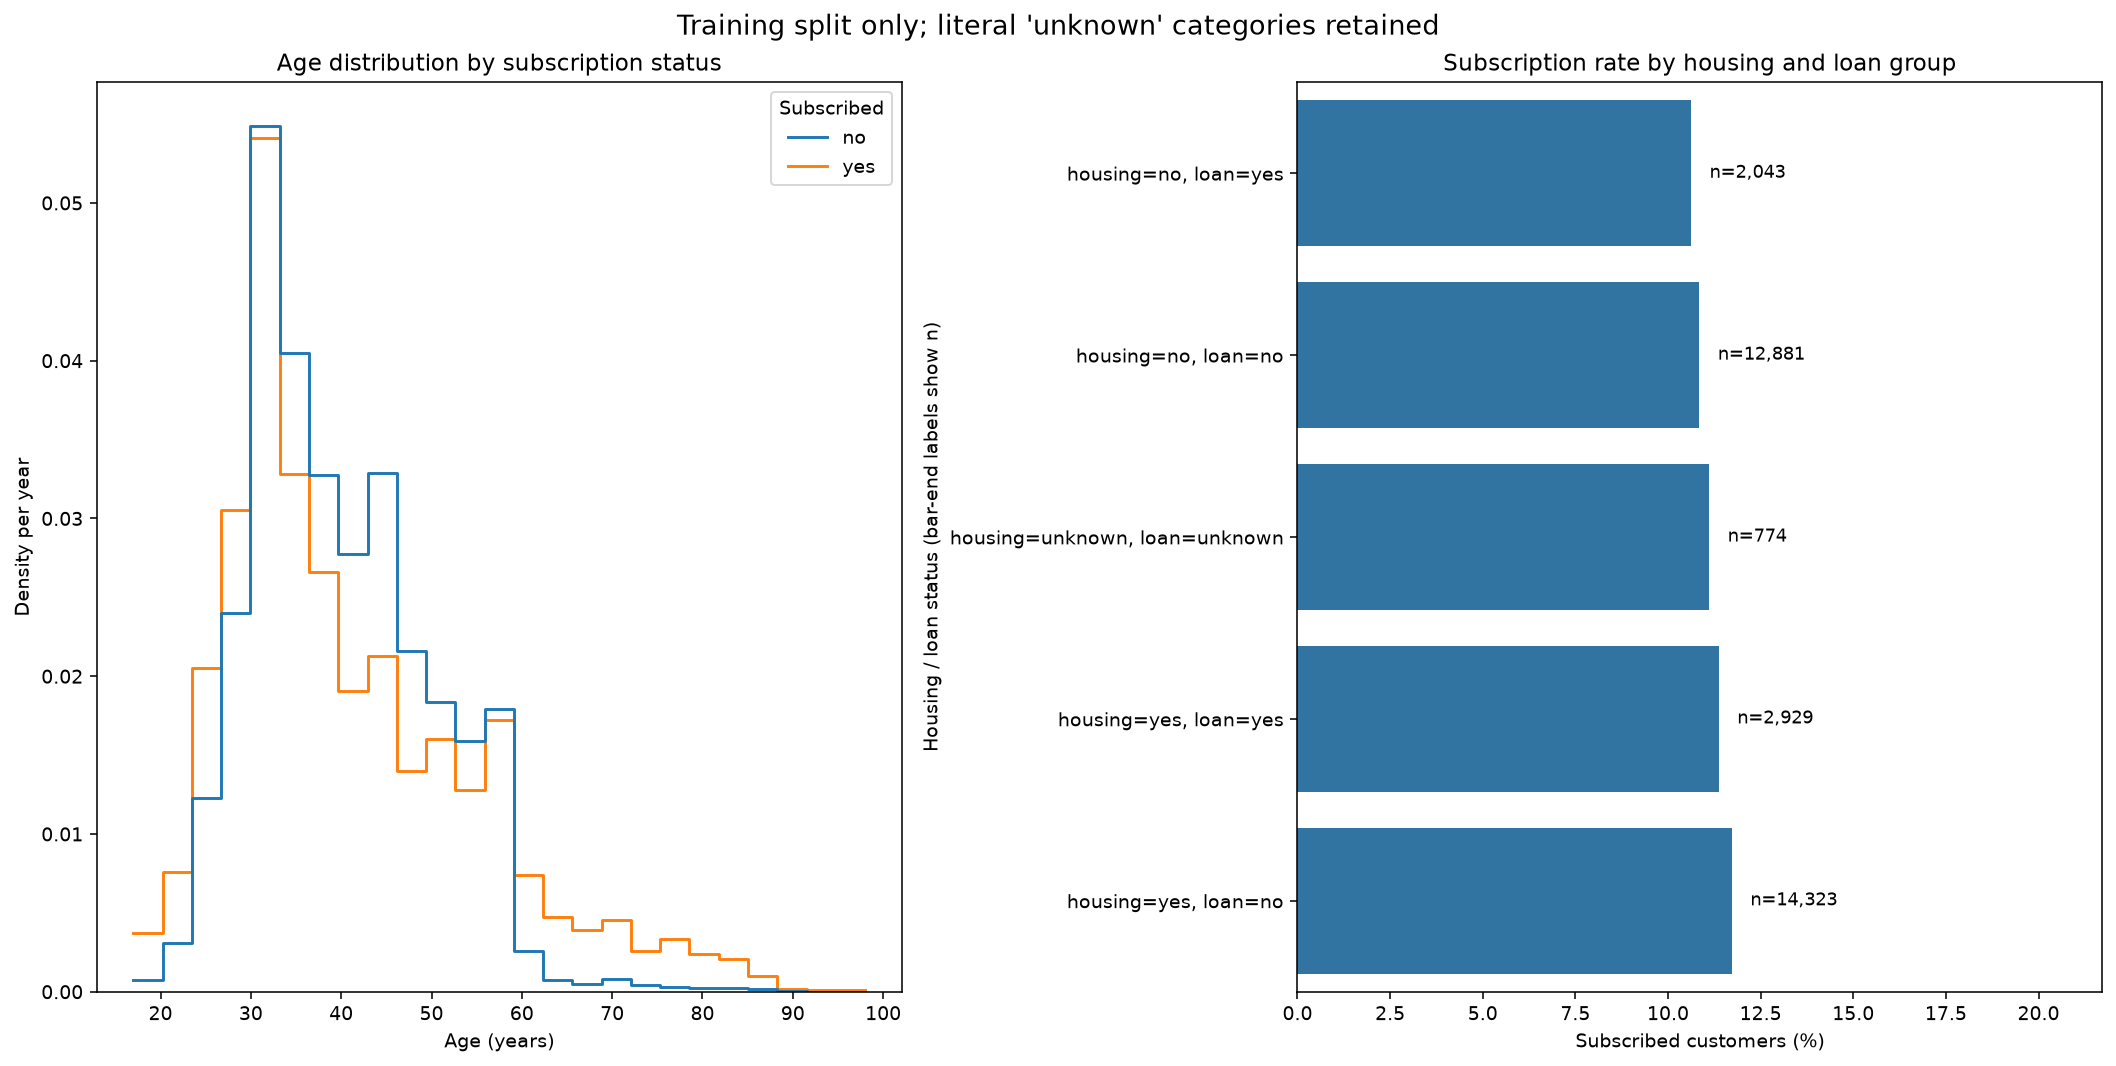

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

p11_fig, p11_axes = plt.subplots(1, 2, figsize=(15, 7.5), constrained_layout=True)
sns.histplot(
    data=p11_training_eda,
    x="age",
    hue="subscription",
    hue_order=["no", "yes"],
    bins=25,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    ax=p11_axes[0],
)
p11_axes[0].set_title("Age distribution by subscription status")
p11_axes[0].set_xlabel("Age (years)")
p11_axes[0].set_ylabel("Density per year")
p11_legend = p11_axes[0].get_legend()
if p11_legend is not None:
    p11_legend.set_title("Subscribed")

p11_group_plot = p11_housing_loan_summary.sort_values(
    "subscription_rate_pct", ascending=True
).copy()
sns.barplot(
    data=p11_group_plot,
    x="subscription_rate_pct",
    y="housing_loan_label",
    order=p11_group_plot["housing_loan_label"],
    color=sns.color_palette()[0],
    errorbar=None,
    ax=p11_axes[1],
)
for p11_bar, p11_row in zip(p11_axes[1].patches, p11_group_plot.itertuples()):
    p11_axes[1].text(
        p11_bar.get_width() + 0.5,
        p11_bar.get_y() + p11_bar.get_height() / 2,
        f"n={p11_row.n:,}",
        va="center",
        fontsize=9,
    )
p11_max_rate = float(p11_group_plot["subscription_rate_pct"].max())
p11_axes[1].set_xlim(0, p11_max_rate + 10)
p11_axes[1].set_title("Subscription rate by housing and loan group")
p11_axes[1].set_xlabel("Subscribed customers (%)")
p11_axes[1].set_ylabel("Housing / loan status (bar-end labels show n)")
p11_fig.suptitle("Training split only; literal 'unknown' categories retained", fontsize=14)
plt.show()


### Exploratory Inference


In [10]:
import numpy as np
from scipy.stats import chi2_contingency

p11_contingency = pd.crosstab(
    p11_training_eda["housing_loan_group"],
    p11_training_eda["subscription"],
).reindex(columns=["no", "yes"], fill_value=0)
p11_chi2, p11_chi2_p, p11_chi2_dof, p11_expected = chi2_contingency(
    p11_contingency,
    correction=False,
)
p11_min_expected = float(p11_expected.min())
p11_cramers_v = float(
    np.sqrt(p11_chi2 / (p11_contingency.to_numpy().sum() * min(p11_contingency.shape[0] - 1, p11_contingency.shape[1] - 1)))
)
p11_inference_summary = pd.DataFrame([{
    "Test": "Housing × loan group vs subscription (training rows)",
    "Chi-square": p11_chi2,
    "Degrees of freedom": p11_chi2_dof,
    "p-value": p11_chi2_p,
    "Minimum expected count": p11_min_expected,
    "Cramer's V": p11_cramers_v,
}])
assert p11_min_expected > 0
print(p11_inference_summary.to_string(index=False,formatters={"Chi-square":"{:.3f}".format,"p-value":"{:.3g}".format,"Minimum expected count":"{:.2f}".format,"Cramer's V":"{:.4f}".format}))




                                                Test Chi-square  Degrees of freedom p-value Minimum expected count Cramer's V
Housing × loan group vs subscription (training rows)      6.162                   4   0.187                  87.20     0.0137


### Tuned Logistic Coefficient


In [11]:
# Interpret the tuned logistic model fit on training data, not a test-set refit.
p11_best_logistic = p11_searches["Logistic Regression"].best_estimator_
p11_logistic = p11_best_logistic.named_steps["classifier"]
p11_preprocessor_fitted = p11_best_logistic.named_steps["preprocess"]
p11_feature_names = p11_preprocessor_fitted.get_feature_names_out()
p11_age_index = list(p11_feature_names).index("numeric__age")
p11_age_coefficient_per_sd = float(p11_logistic.coef_[0, p11_age_index])
p11_age_sd_years = float(p11_preprocessor_fitted.named_transformers_["numeric"].scale_[0])
p11_age_log_odds_per_decade = p11_age_coefficient_per_sd * (10 / p11_age_sd_years)
p11_age_odds_ratio_per_decade = float(np.exp(p11_age_log_odds_per_decade))
p11_age_coefficient_table = pd.DataFrame([{
    "Tuned logistic feature": "Age (standardized)",
    "Coefficient per training SD": p11_age_coefficient_per_sd,
    "Training age SD (years)": p11_age_sd_years,
    "Conditional odds ratio per +10 years": p11_age_odds_ratio_per_decade,
}])
print(p11_age_coefficient_table.to_string(index=False,formatters={"Coefficient per training SD":"{:.4f}".format,"Training age SD (years)":"{:.2f}".format,"Conditional odds ratio per +10 years":"{:.4f}".format}))


Tuned logistic feature Coefficient per training SD Training age SD (years) Conditional odds ratio per +10 years
    Age (standardized)                      0.1414                   10.43                               1.1452


## Findings

The training split contains 32,950 records and seven pre-call predictors. Mean age was 39.9 years for non-subscribers and 40.9 for subscribers; median ages were 38 and 37 years, respectively. Observed subscription rates across housing/loan groups ranged from 10.62% to 11.72%, with group counts shown in the chart and table. Literal `unknown` values remain categories; selected features and target contain no nulls, so no imputation was applied.

The training-only housing-by-loan association test gave χ²(4)=6.162, p=0.187, minimum expected count=87.20, and Cramér's V=0.0137. The observed association is very small and the test does not meet the conventional 5% significance threshold. The chi-square calculation assumes independent rows; this campaign data records contacts and does not provide a unique customer identifier to verify independence across repeated contacts. Interpret the result as an exploratory association, not a causal effect.

The tuned logistic model's standardized age coefficient was 0.1414 per training-set standard deviation (10.43 years); this corresponds to a conditional odds ratio of 1.1452 per additional 10 years, holding the other included predictors constant. This is a model coefficient, not a percentage-point change or an inferential significance test, and it does not establish causation.

Decision Tree was selected by the highest mean training CV average precision (0.2086). On the untouched test split its average precision was 0.1958 versus 0.1126 for a constant-score prevalence baseline, while accuracy was 0.6548 versus 0.8874 for the majority-class baseline. The ranking metric favors identifying likely subscribers; the accuracy tradeoff shows why the operating threshold and capacity matter. This offline retrospective result is not evidence of guaranteed business lift.


## Recommendations

Treat the model as a prioritization candidate, not an automatic calling policy. Run a controlled pilot with a fixed call capacity and random assignment between the model-ranked queue and current calling practice. Track subscribers per 100 calls and precision among the contacts reached at that capacity, while retaining the comparison group. Review performance over time and across relevant customer groups before considering rollout.

The model uses seven pre-call fields—age, job, marital status, education, credit default, housing loan, and personal loan—and excludes call duration because it is only known after contact. Keep the evaluation focused on these pre-call signals; do not treat the observed associations or retrospective holdout scores as causal evidence.


##### Questions